In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
import scienceplots


In [2]:
plt.style.use(["science", "ieee", "grid"])

In [3]:
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root='mnist_train_data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='mnist_test_data', train=False, download=True, transform=transform)

In [4]:
def plot_mnist_examples(dataset):
    found_classes = {}
    for image, label in dataset:
        if label not in found_classes:
            found_classes[label] = image
        if len(found_classes) == 10:
            break

    fig, axes = plt.subplots(2, 5, figsize=(6, 3))    
    for i in range(10):
        ax = axes[i // 5, i % 5]
        # MNIST images are (1, 28, 28), so we squeeze the channel dimension for plotting
        img = found_classes[i].squeeze().numpy()
        ax.imshow(img, cmap='gray')
        ax.set_title(f"$l = {i}$")
        ax.axis('off')

    plt.tight_layout()
    plt.savefig('./figures_vae_example/mnist_examples.png', dpi=600)
    plt.show()

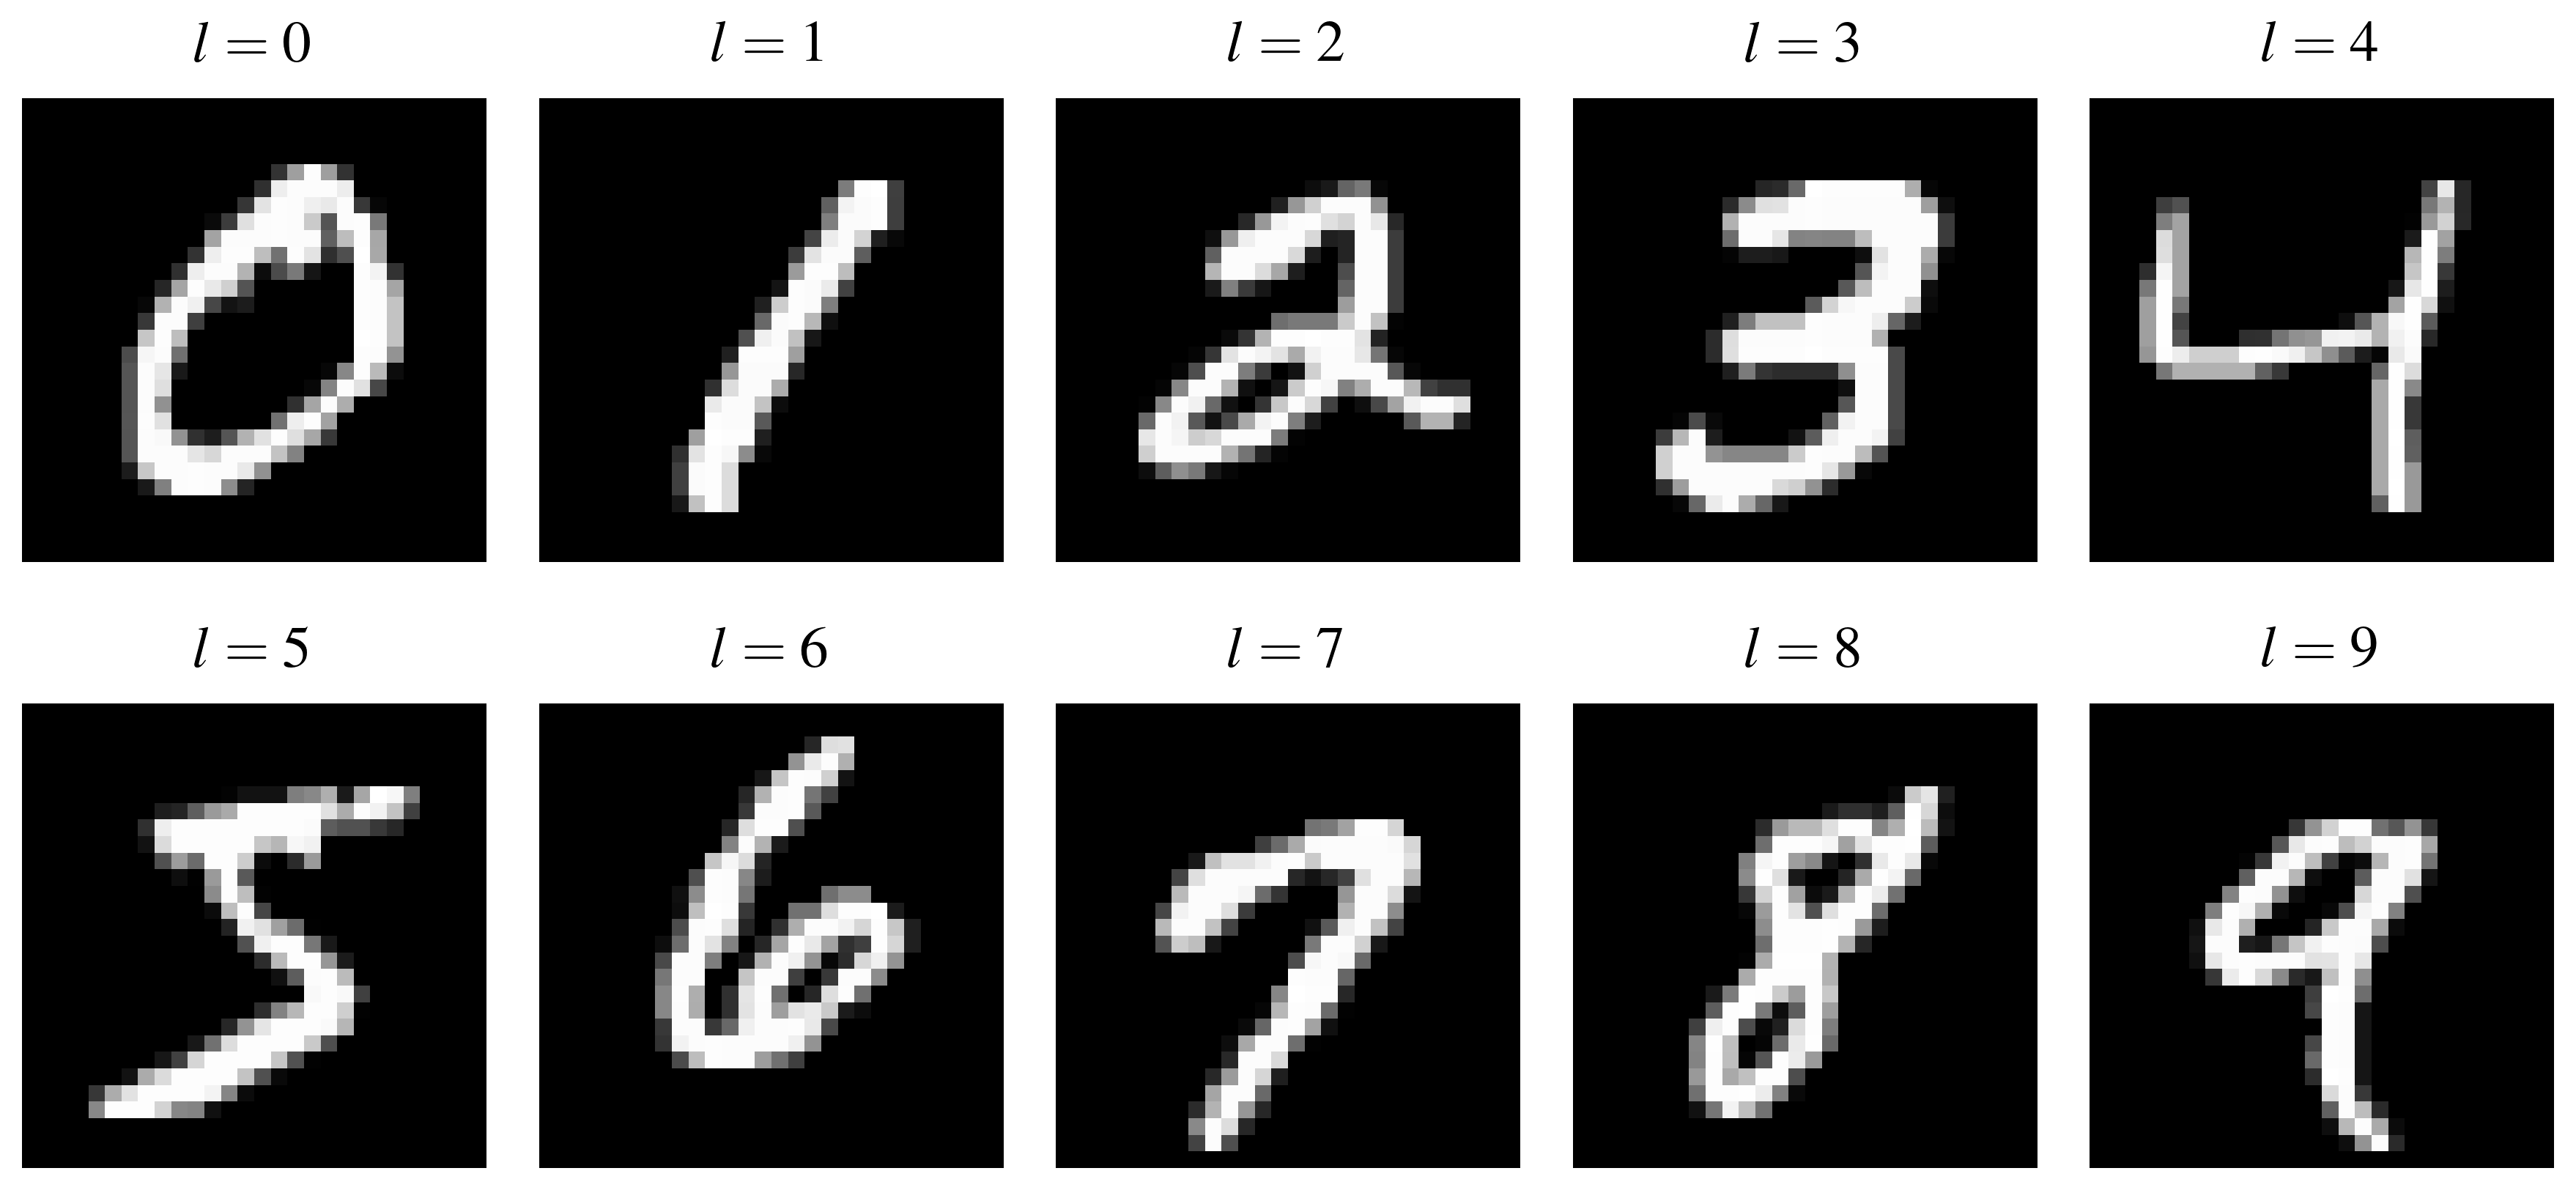

In [5]:
plot_mnist_examples(train_dataset)

# Training

In [6]:
device = torch.device('cpu' if torch.cuda.is_available() else 'cpu')
batch_size = 32
latent_dim = 2  # Small dimension so we can easily plot later
lr = 1e-3

In [7]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [8]:
class VAE(nn.Module):
    def __init__(self, input_dim=784, h_dim=400, z_dim=20):
        super(VAE, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, input_dim//2),
            nn.ReLU(),
            nn.Linear(input_dim//2, input_dim//4),
            nn.ReLU(),
            nn.Linear(input_dim//4, h_dim),
        )
        self.fc_mu = nn.Linear(h_dim, z_dim)
        self.fc_logvar = nn.Linear(h_dim, z_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, input_dim//4),
            nn.ReLU(),
            nn.Linear(input_dim//4, input_dim//2),
            nn.ReLU(),
            nn.Linear(input_dim//2, input_dim),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std


    def forward(self, x):
        h = self.encoder(x.view(-1, 784))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

In [9]:
rec_loss_fn = torch.nn.BCELoss(reduction="mean")

def loss_function(recon_x, x, mu, logvar, beta):
    BCE = rec_loss_fn(recon_x, x.view(-1, 784))
    # Analytical KL Divergence for Diagonal Gaussian
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return BCE + beta * KLD, BCE, KLD

In [10]:
model = VAE(z_dim=latent_dim, h_dim=latent_dim*4).to(device)
optimizer = optim.Adam(model.parameters(), lr=lr)
beta = 1e-4
model.train()
train_loss_list = []
bce_loss_list = []
kld_loss_list = []

for epoch in tqdm(range(200)):
    train_loss = 0
    bce_loss = 0
    kld_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(device)
        optimizer.zero_grad()
        recon_batch, mu, logvar = model(data)
        loss, bce, kld = loss_function(recon_batch, data, mu, logvar, beta=beta)
        loss.backward()
        train_loss += loss.item() / (len(train_loader) + len(data))
        bce_loss += bce.item() / (len(train_loader) + len(data))
        kld_loss += kld.item() / (len(train_loader) + len(data))
        optimizer.step()
    train_loss_list.append(train_loss)
    bce_loss_list.append(bce_loss)
    kld_loss_list.append(kld_loss)

100%|██████████| 200/200 [3:07:48<00:00, 56.34s/it]  


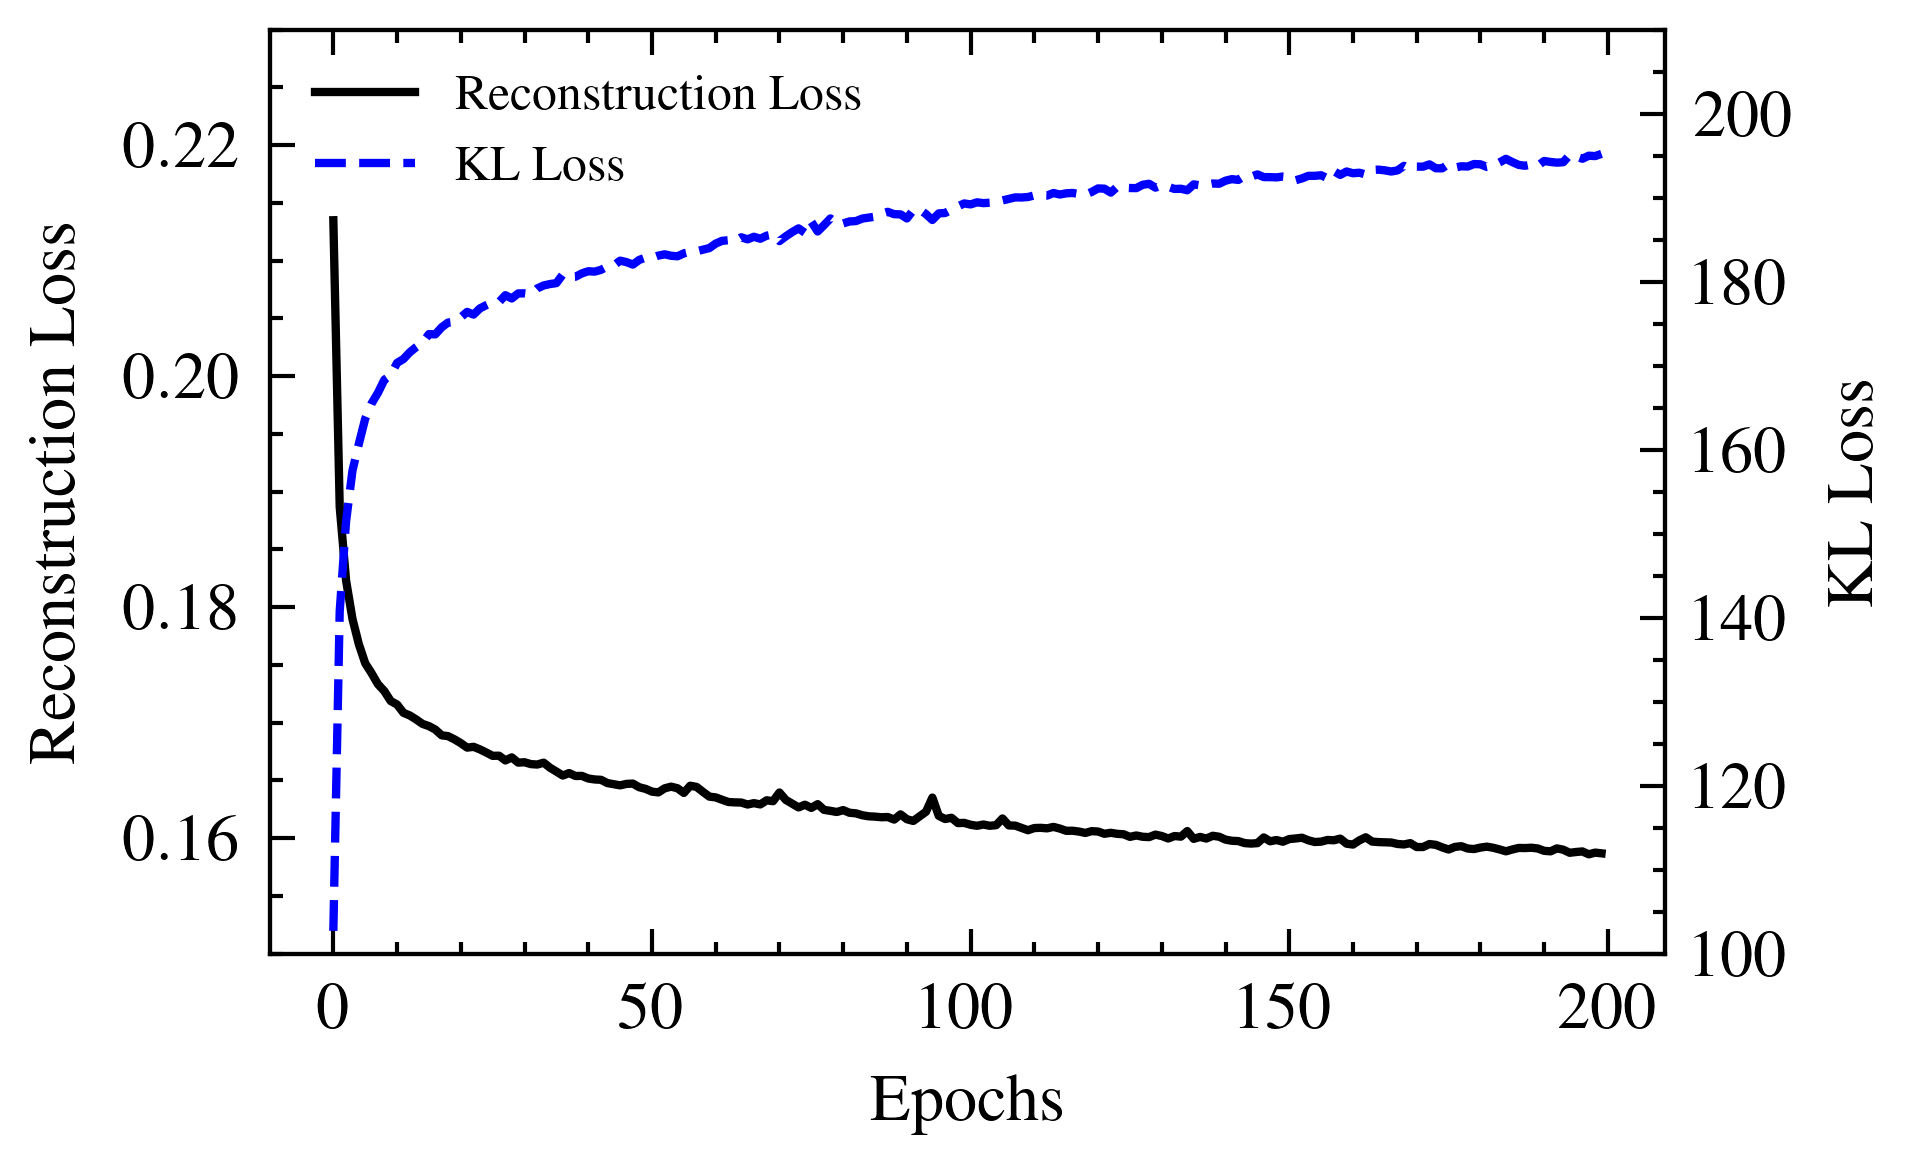

In [55]:
fig = plt.figure(figsize=(3,2))
ax = fig.add_subplot()
ax.plot([],[],color="black", linestyle="-")
ax.plot([],[],color="blue", linestyle="--")
ax.set_ylim(ymin=0.15, ymax=0.23)
ax.legend(["Reconstruction Loss", "KL Loss"], loc="upper left", fontsize=6, frameon=False)

ax.plot(bce_loss_list, color="black", linestyle="-")
ax.grid(False)
ax.set_ylabel("Reconstruction Loss")
ax2 = ax.twinx()
ax2.plot(kld_loss_list, color="blue", linestyle="--")
ax2.grid(False)
ax2.set_ylim(ymin=100, ymax=210)
ax2.set_ylabel("KL Loss")
ax.set_xlabel("Epochs")
fig.savefig('./figures_vae_example/loss_curves.png', dpi=400)

# Output visualization

In [13]:
def get_latent_embeddings(model, dataloader, device="cuda"):
    model.eval()
    latents = []
    labels = []
    
    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)
            # Assuming your model has an 'encode' method or returns (z, reconstruction)
            h = model.encoder(x.view(-1, 784))
            mu = model.fc_mu(h)
            # logvar = model.fc_logvar(h) 
            latents.append(mu.cpu())
            labels.append(y)
            
    return torch.cat(latents, dim=0).numpy(), torch.cat(labels, dim=0).numpy()

In [15]:
# def plot_reconstructions(model, dataset, num_samples=5, device="cuda"):
#     model.eval()
#     indices = np.random.choice(len(dataset), num_samples, replace=False)
    
#     fig, axes = plt.subplots(2, num_samples, figsize=(num_samples * 3, 6))
    
#     with torch.no_grad():
#         for i, idx in enumerate(indices):
#             x, _ = dataset[idx]
#             x_input = x.unsqueeze(0).to(device)
#             x_recon = model(x_input)[0] # Or model.reconstruct(x_input)
            
#             # Original
#             axes[0, i].imshow(x.squeeze().cpu().numpy(), cmap='gray')
#             axes[0, i].axis('off')
#             if i == 0: axes[0, i].set_title("Original")
            
#             # Reconstruction
#             axes[1, i].imshow(x_recon.reshape(28, 28).cpu().numpy(), cmap='gray')
#             axes[1, i].axis('off')
#             if i == 0: axes[1, i].set_title("Reconstructed")
            
#     plt.tight_layout()
#     plt.show()

In [17]:
batch_size = 64
train_dataloader_test = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
# device = "cuda" if torch.cuda.get_available() else "cpu"

In [18]:
latents, labels = get_latent_embeddings(model, train_dataloader_test, device=device)

In [73]:
import matplotlib.colors as mcolors
n_bins = 10
discrete_seismic = plt.get_cmap('seismic').resampled(n_bins)

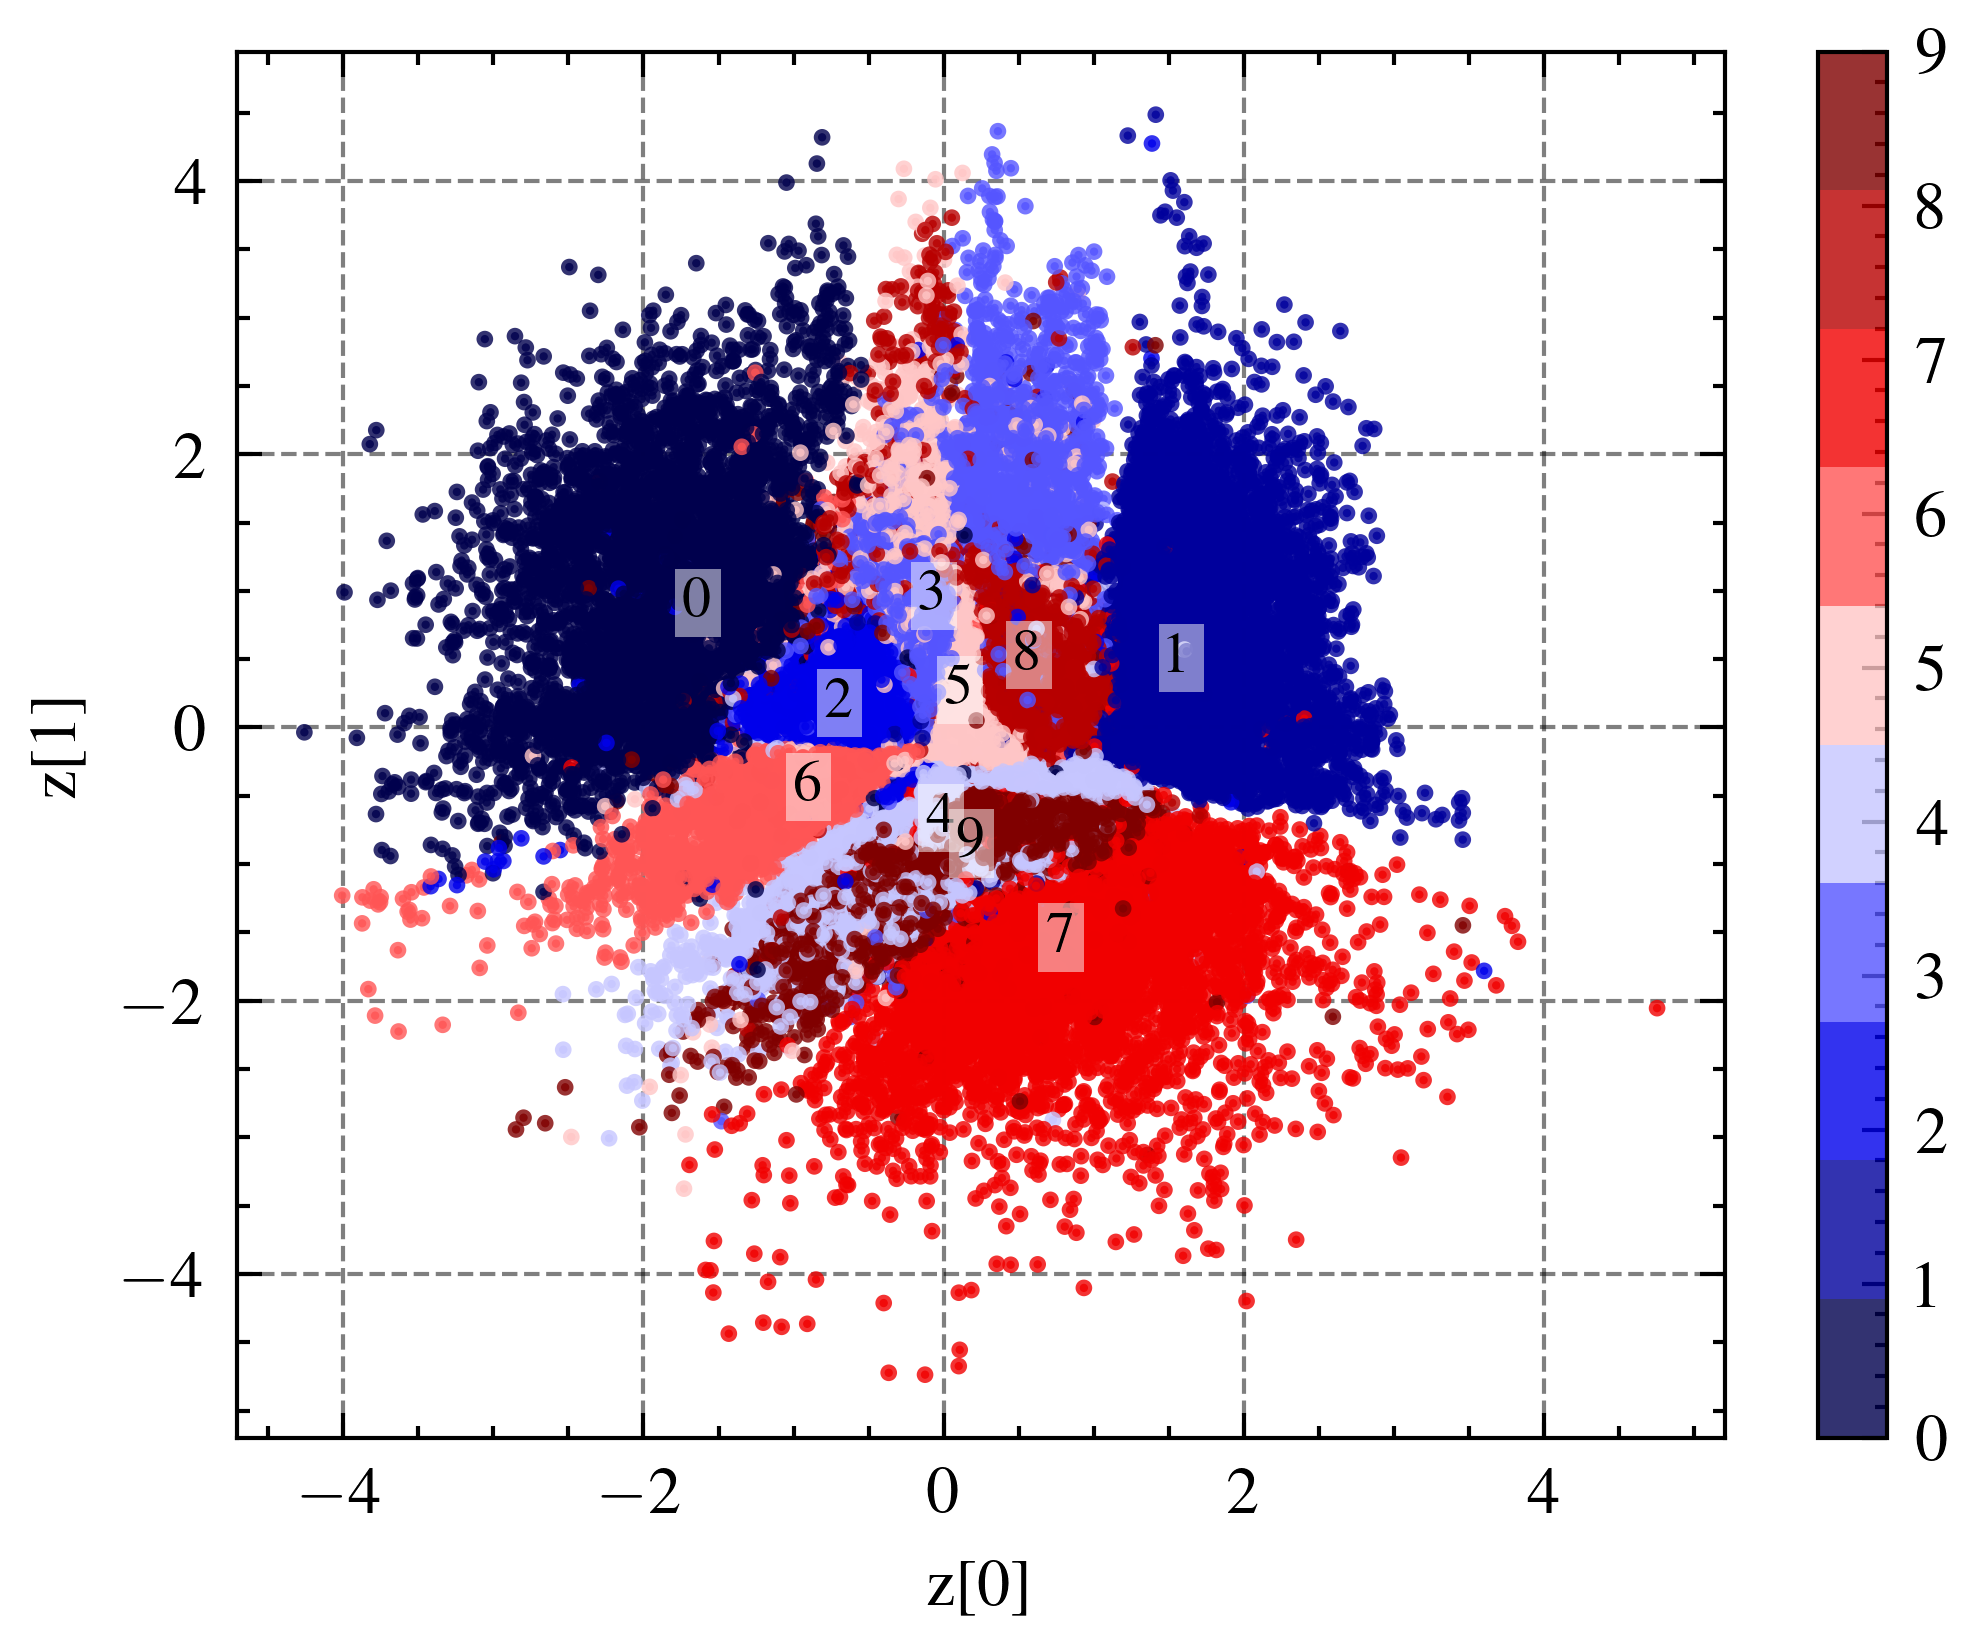

In [93]:
plt.figure(figsize=(4, 3))

# 1. Main scatter plot
scatter = plt.scatter(latents[:, 0], latents[:, 1], c=labels, cmap=discrete_seismic, alpha=0.8, s=1)

# 2. Calculate and plot the label at the median point
unique_labels = np.unique(labels)
for l in unique_labels:
    # Filter latents belonging to the current label
    mask = (labels == l)
    median_x = np.median(latents[mask, 0])
    median_y = np.median(latents[mask, 1])
    
    # Add text label with a small outline for readability
    plt.text(median_x, median_y, str(int(l)), 
             fontsize=7, fontweight='bold',
             ha='center', va='center',
             bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))

plt.colorbar(scatter)
plt.xlabel("z[0]")
plt.ylabel("z[1]")
plt.savefig('./figures_vae_example/latent_space.png', dpi=400)

In [111]:
def plot_reconstructions_per_label(model, dataset, device="cpu"):
    model.eval()
    # Handle both torchvision datasets and custom list-based datasets
    targets = torch.tensor(dataset.targets) if hasattr(dataset, 'targets') else torch.tensor([y for _, y in dataset])
    
    indices = []
    for i in range(10):
        # Find the first index for each digit 0-9
        match = (targets == i).nonzero(as_tuple=True)[0]
        if len(match) > 0:
            indices.append(match[0].item())
    
    fig, axes = plt.subplots(4, 5, figsize=(6, 4))
    
    with torch.no_grad():
        row = 0
        for i, idx in enumerate(indices):
            col = i
            if i > 4:
                row = 2
                col = i - 5
            img, label = dataset[idx]
            img_input = img.unsqueeze(0).to(device)
            
            out = model(img_input)
            recon = out[0] if isinstance(out, (tuple, list)) else out
            
            # Convert to numpy and reshape to 28x28 for plotting
            img_plot = img.cpu().numpy().reshape(28, 28)
            recon_plot = recon.cpu().numpy().reshape(28, 28)
            
            # Plot Original
            axes[row, col].imshow(img_plot, cmap='gray')
            axes[row, col].set_title(f"Digit: {i}")
            axes[row, col].axis('off')
            
            # Plot Reconstruction
            axes[row + 1, col].imshow(recon_plot, cmap='gray')
            axes[row + 1, col].set_title(f"Reconstruction: {i}")
            axes[row + 1, col].axis('off')
            
    axes[0, 0].set_ylabel("Original", size='large')
    axes[1, 0].set_ylabel("Reconstruction", size='large')
    plt.tight_layout()
    plt.savefig('./figures_vae_example/reconstructions.png', dpi=400)

C:\Users\eduar\AppData\Local\Temp\ipykernel_27080\3621781527.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  targets = torch.tensor(dataset.targets) if hasattr(dataset, 'targets') else torch.tensor([y for _, y in dataset])


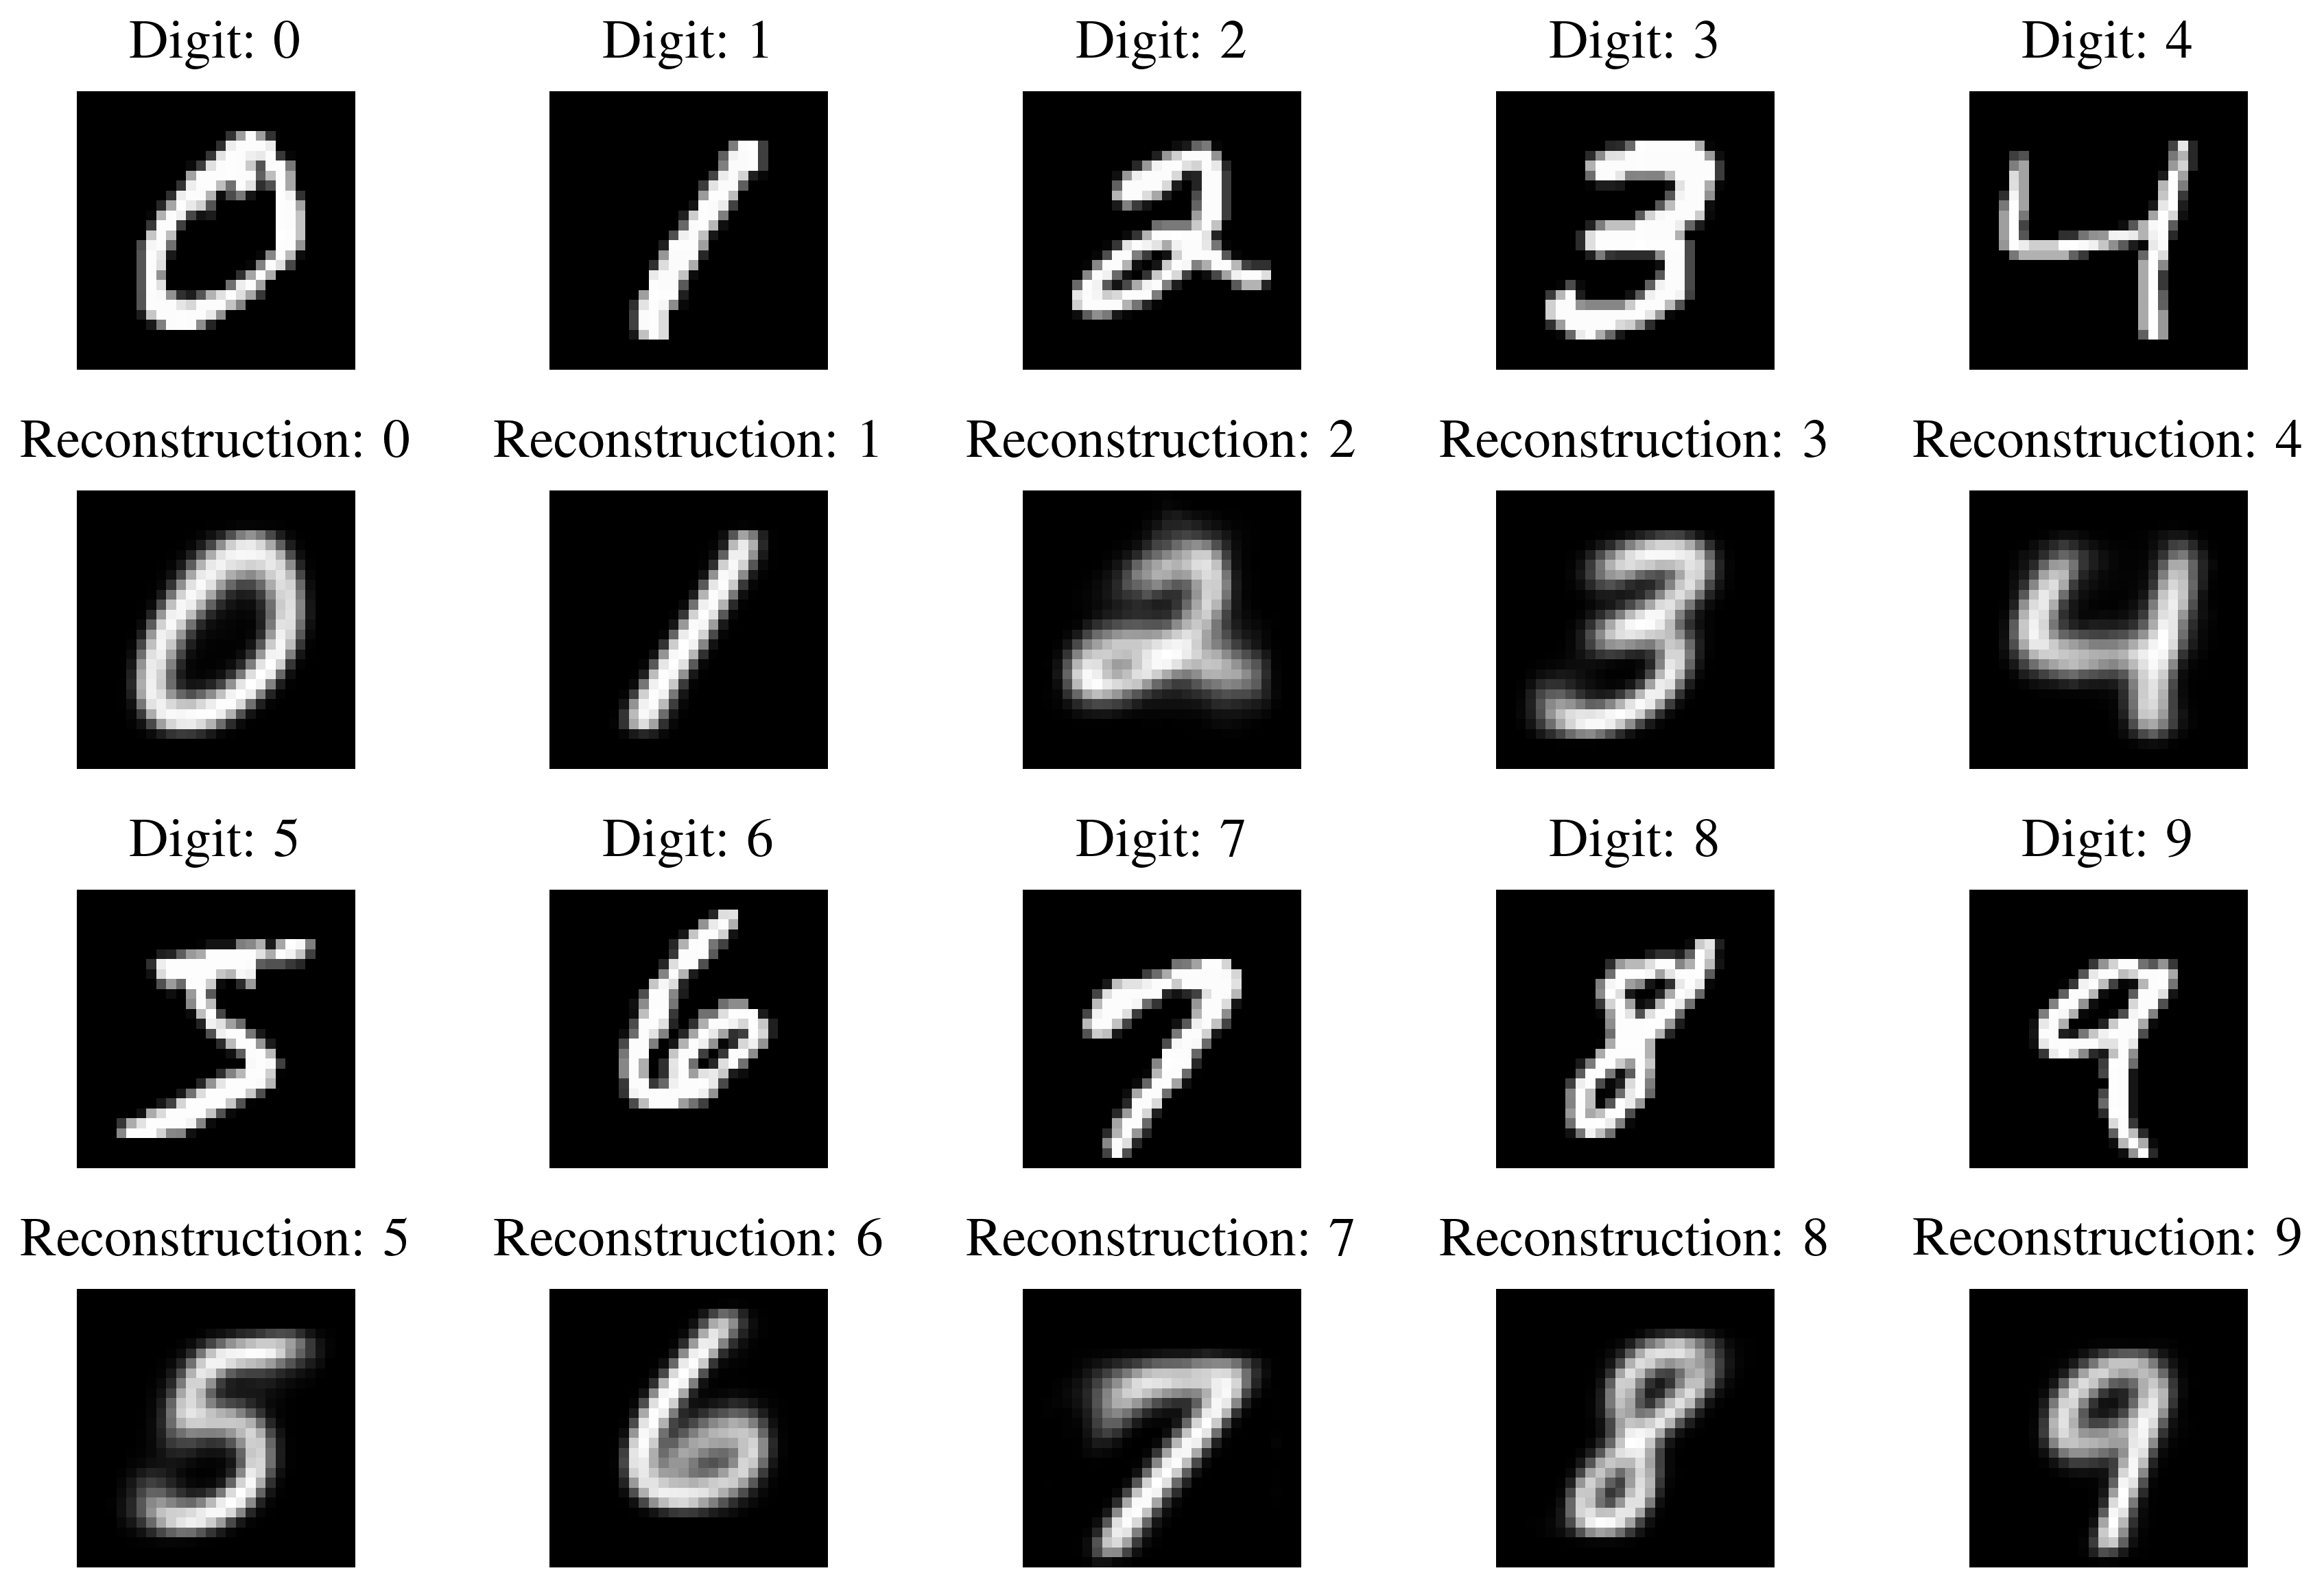

In [112]:
plot_reconstructions_per_label(model, train_dataset, device=device)